# Importacion de librerias

In [1]:
import os, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import yfinance as yf
warnings.filterwarnings('ignore', category=FutureWarning)
os.makedirs('figuras_DIS',exist_ok=True)
plt.rcParams.update({'figure.figsize':(12,5),'axes.grid':True,'font.size':10})
def guardar(nombre):
    plt.tight_layout(); plt.savefig(f'figuras_DIS/{nombre}.png',dpi=180,bbox_inches='tight');plt.show()

##  Obtención de datos
Se utiliza **Close sin ajuste** para analizar el precio de cierre observado. Yahoo Finance emplea un límite final exclusivo. La serie contiene únicamente sesiones bursátiles.

In [2]:
raw=yf.download('DIS',start='2023-01-01',end='2023-05-01',auto_adjust=False,progress=False)
if raw.empty: raise RuntimeError('Yahoo Finance no devolvió datos; revise conexión o intente nuevamente.')
serie=raw['Close']; serie=serie.iloc[:,0] if isinstance(serie,pd.DataFrame) else serie
serie=serie.dropna().astype(float).sort_index()
train_period=serie.loc['2023-01-01':'2023-03-31']
abril_real=serie.loc['2023-04-01':'2023-04-30']
print('Observaciones enero-marzo:',len(train_period),'abril:',len(abril_real))
print(train_period.describe().round(3))
assert len(train_period)>35, 'Serie insuficiente'

Observaciones enero-marzo: 62 abril: 19
count     62.000
mean     100.819
std        6.321
min       88.970
25%       95.575
50%       99.710
75%      107.192
max      113.210
Name: DIS, dtype: float64


In [3]:
train_period.to_csv('DIS_enero_marzo_2023.csv',header=['Close']); abril_real.to_csv('DIS_abril_real_2023.csv',header=['Close'])

##  Exploración visual y estadística

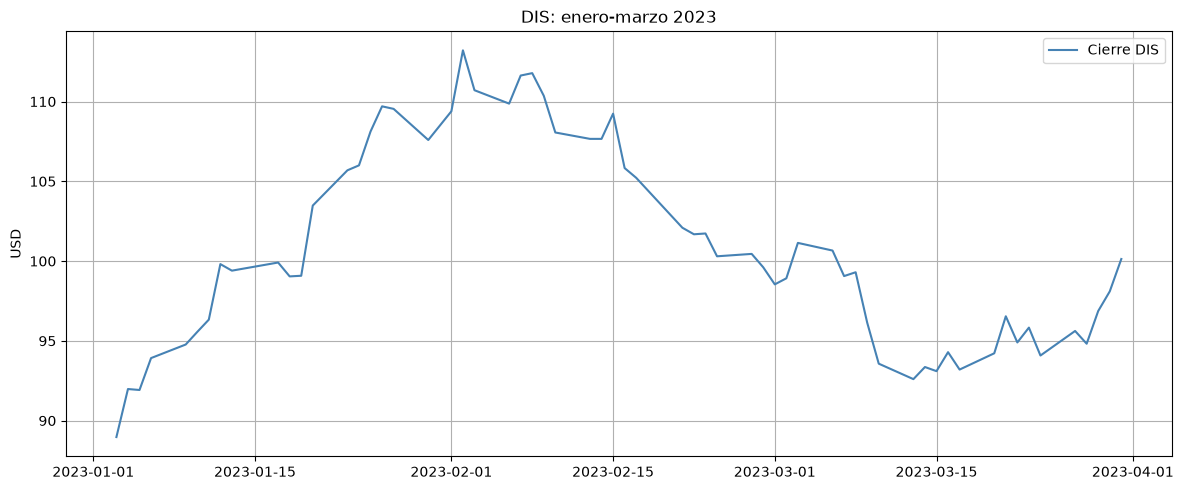

In [5]:
plt.plot(train_period.index,train_period,color='steelblue',label='Cierre DIS');
plt.title('DIS: enero-marzo 2023');
plt.ylabel('USD');
plt.legend();
guardar('01_precios')

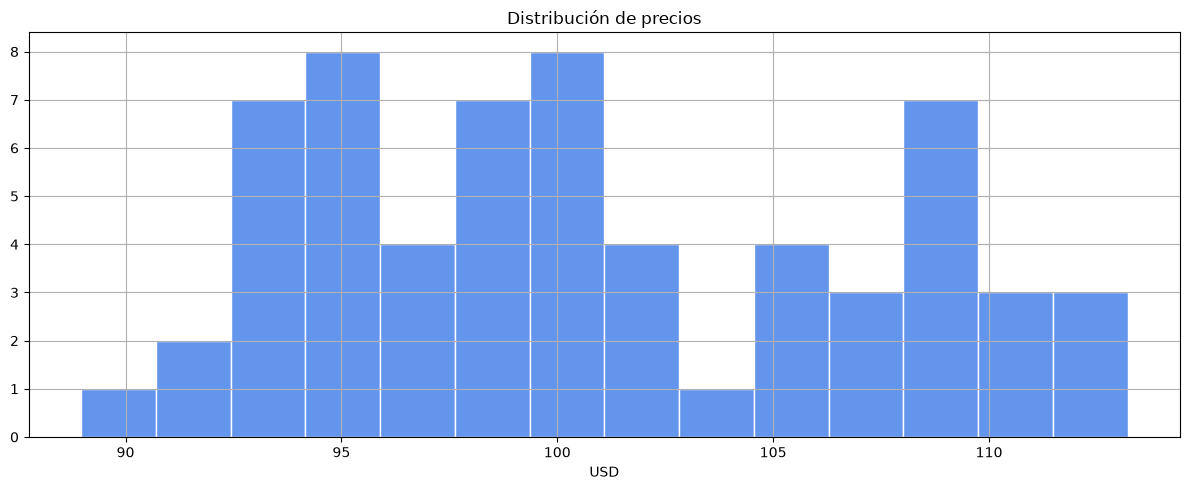

In [6]:
plt.hist(train_period,bins=14,color='cornflowerblue',edgecolor='white');
plt.title('Distribución de precios');
plt.xlabel('USD');
guardar('02_histograma')

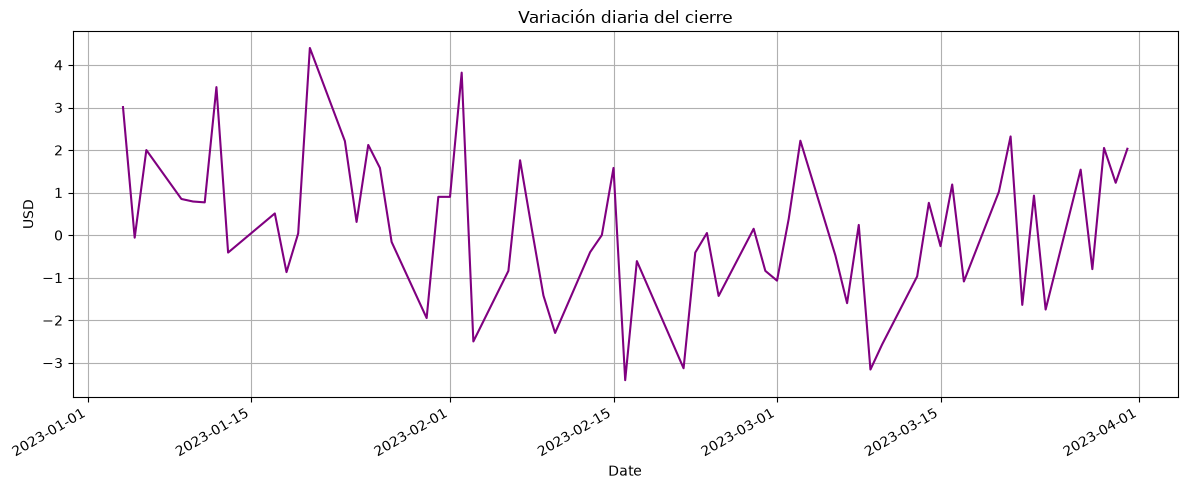

In [7]:
train_period.diff().dropna().plot(color='purple');
plt.title('Variación diaria del cierre');
plt.ylabel('USD');
guardar('03_diferencias')

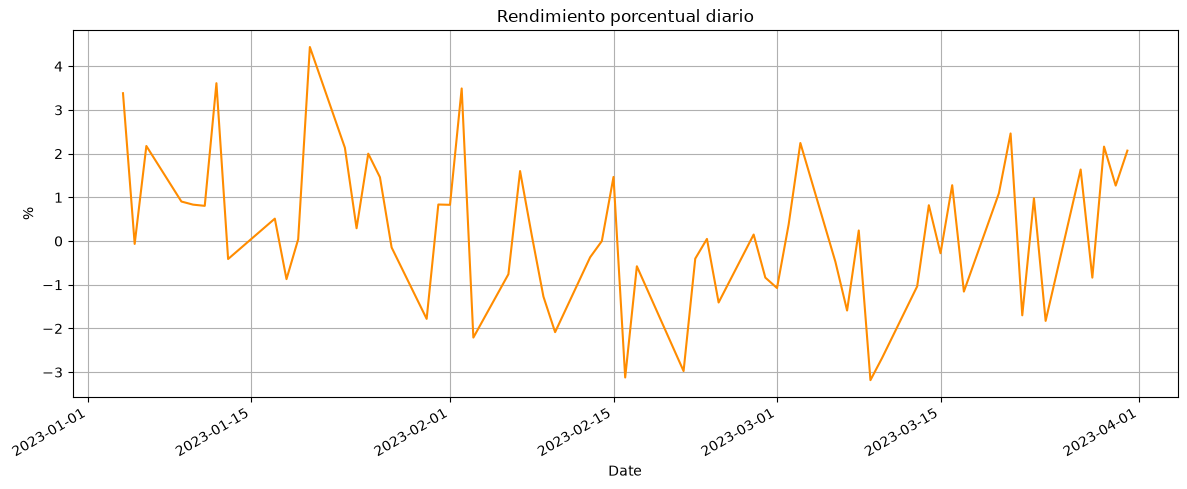

In [8]:
train_period.pct_change().dropna().mul(100).plot(color='darkorange');
plt.title('Rendimiento porcentual diario');
plt.ylabel('%');
guardar('04_rendimientos')

##  División cronológica 70/30
Se reserva el último 30% para evaluación. No se mezclan observaciones aleatoriamente.

In [12]:
n_train=int(len(train_period)*.7);
entrenamiento=train_period.iloc[:n_train];
prueba=train_period.iloc[n_train:];
print(f'Entrenamiento {len(entrenamiento)} ({len(entrenamiento)/len(train_period):.1%}),prueba {len(prueba)}')

Entrenamiento 43 (69.4%),prueba 19


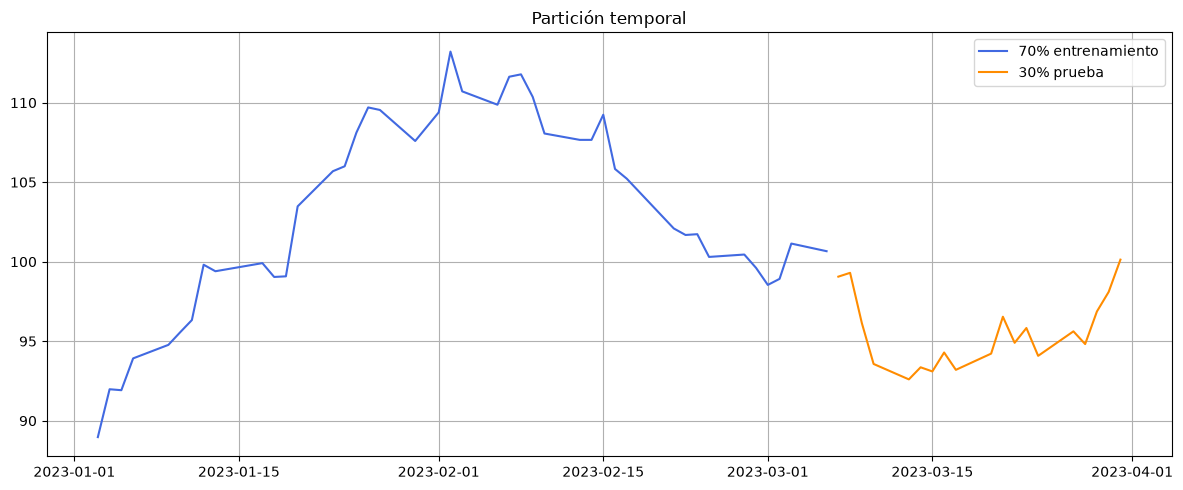

In [13]:
plt.plot(entrenamiento,label='70% entrenamiento',color='royalblue');
plt.plot(prueba,label='30% prueba',color='darkorange');
plt.legend();plt.title('Partición temporal');
guardar('05_particion')

##  Estacionariedad (ADF)
La hipótesis nula de la prueba ADF es la presencia de raíz unitaria. Si p ≥ 0.05, la evidencia no permite rechazarla. El modelo solicitado se ajusta sobre niveles para pronosticar precios, pero se advierte si no se verifica estacionariedad.

In [14]:
adf=adfuller(entrenamiento,autolag='AIC');
print('ADF estadístico:',round(adf[0],4),'p-valor:',round(adf[1],4));
print('Advertencia: posibles precios no estacionarios' if adf[1]>=.05 else 'Se rechaza raíz unitaria al 5%')

ADF estadístico: -3.0496 p-valor: 0.0305
Se rechaza raíz unitaria al 5%


##  ACF y PACF
La PACF sugiere órdenes candidatos; los criterios de información permiten compararlos cuantitativamente. Los retardos significativos se interpretan con cautela.

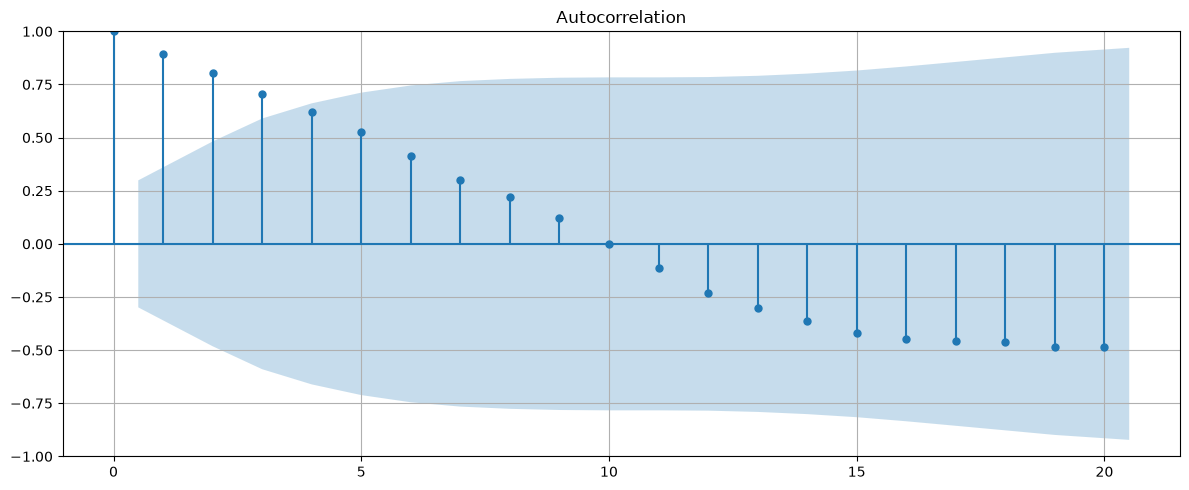

In [15]:
fig,ax=plt.subplots();plot_acf(entrenamiento,lags=min(20,len(entrenamiento)//2-1),ax=ax);guardar('06_acf')

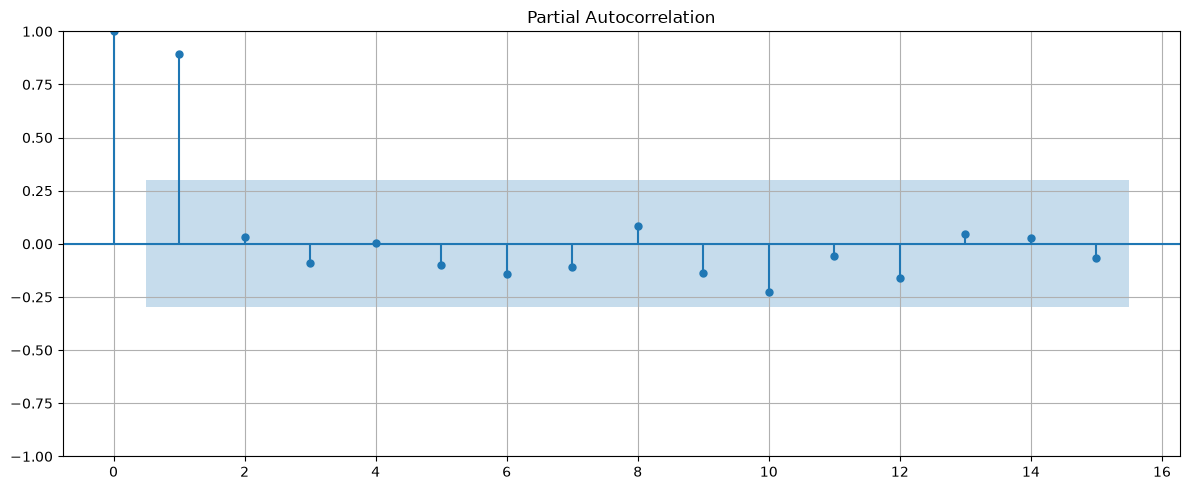

In [16]:
fig,ax=plt.subplots();plot_pacf(entrenamiento,lags=min(15,len(entrenamiento)//2-1),method='ywm',ax=ax);guardar('07_pacf')

##  Selección de p mediante AIC y BIC
Para comparar criterios de información se mantiene una **muestra efectiva común** usando `hold_back=max_p`. Se elige el menor BIC como regla principal por su penalización de complejidad; se informa también el mínimo AIC.

In [17]:
max_p=min(15,max(2,len(entrenamiento)//5))
registros=[]
for p in range(1,max_p+1):
    try:
        m=AutoReg(entrenamiento,lags=p,trend='c',hold_back=max_p,old_names=False).fit()
        registros.append({'p':p,'AIC':m.aic,'BIC':m.bic,'sigma2':m.sigma2})
    except Exception as e: print('p no ajustado:',p,str(e))
criterios=pd.DataFrame(registros)
if criterios.empty: raise RuntimeError('No fue posible ajustar modelos AR')
p_aic=int(criterios.loc[criterios.AIC.idxmin(),'p']);p_bic=int(criterios.loc[criterios.BIC.idxmin(),'p'])
p_optimo=p_bic
print(criterios.round(3).to_string(index=False));print('AIC propone:',p_aic,'BIC propone:',p_bic,'p seleccionado:',p_optimo)
criterios.to_csv('DIS_comparacion_AR.csv',index=False)


 p     AIC     BIC  sigma2
 1 141.875 146.541   2.841
 2 143.427 149.648   2.805
 3 145.426 153.203   2.805
 4 147.414 156.746   2.804
 5 147.069 157.956   2.622
 6 145.890 158.333   2.395
 7 147.462 161.460   2.366
 8 149.461 165.014   2.366
AIC propone: 1 BIC propone: 1 p seleccionado: 1


C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(d

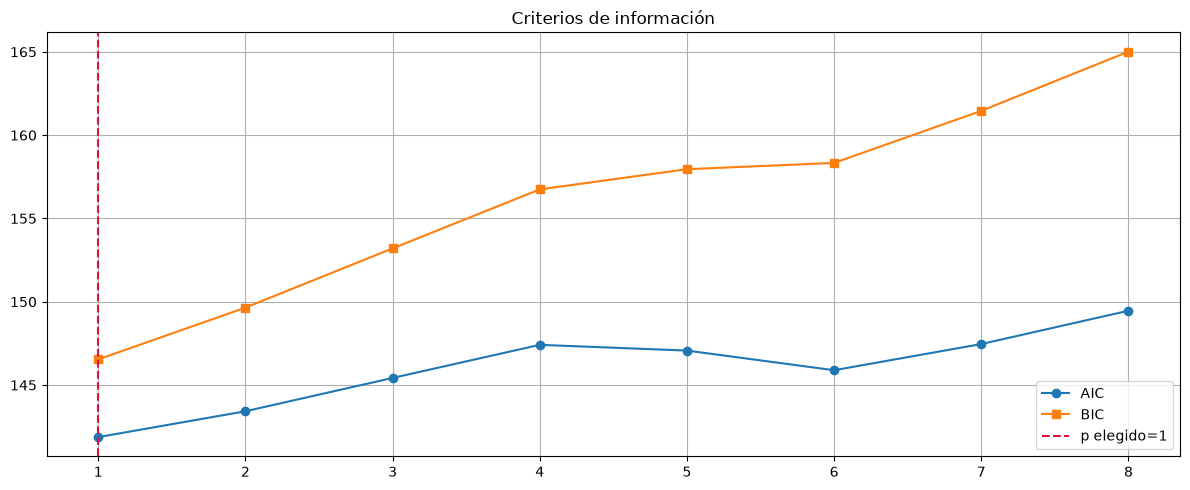

In [18]:
plt.plot(criterios.p,criterios.AIC,'o-',label='AIC');
plt.plot(criterios.p,criterios.BIC,'s-',label='BIC');
plt.axvline(p_optimo,color='crimson',ls='--',label=f'p elegido={p_optimo}');
plt.legend();plt.title('Criterios de información');
guardar('08_aic_bic')

##  Ajuste y prueba fuera de muestra
Se pronostica el bloque de prueba desde el final del entrenamiento, sin incorporar observaciones reales del bloque a cada paso. Esto evita una evaluación optimista.

In [19]:
modelo=AutoReg(entrenamiento,lags=p_optimo,trend='c',old_names=False).fit()
pred_prueba=np.asarray(modelo.predict(start=len(entrenamiento),end=len(train_period)-1,dynamic=False))
pred_prueba=pd.Series(pred_prueba,index=prueba.index,name='Predicción')
mae=mean_absolute_error(prueba,pred_prueba);rmse=np.sqrt(mean_squared_error(prueba,pred_prueba));mape=np.mean(np.abs((prueba-pred_prueba)/prueba))*100;r2=r2_score(prueba,pred_prueba)
naive=np.repeat(entrenamiento.iloc[-1],len(prueba));rmse_naive=np.sqrt(mean_squared_error(prueba,naive))
metricas=pd.DataFrame([{'p':p_optimo,'MAE_USD':mae,'RMSE_USD':rmse,'MAPE_pct':mape,'R2':r2,'RMSE_naive_USD':rmse_naive}]);print(metricas.round(4).to_string(index=False));metricas.to_csv('DIS_metricas.csv',index=False)


C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\deterministic.py:308: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a unit increment support extending. The index is set will contain the position relative to the data length.
  fcast_index = self._extend_index(index, steps, forecast_index)


 p  MAE_USD  RMSE_USD  MAPE_pct       R2  RMSE_naive_USD
 1   8.2392    8.6222    8.6792 -14.2821          5.5522


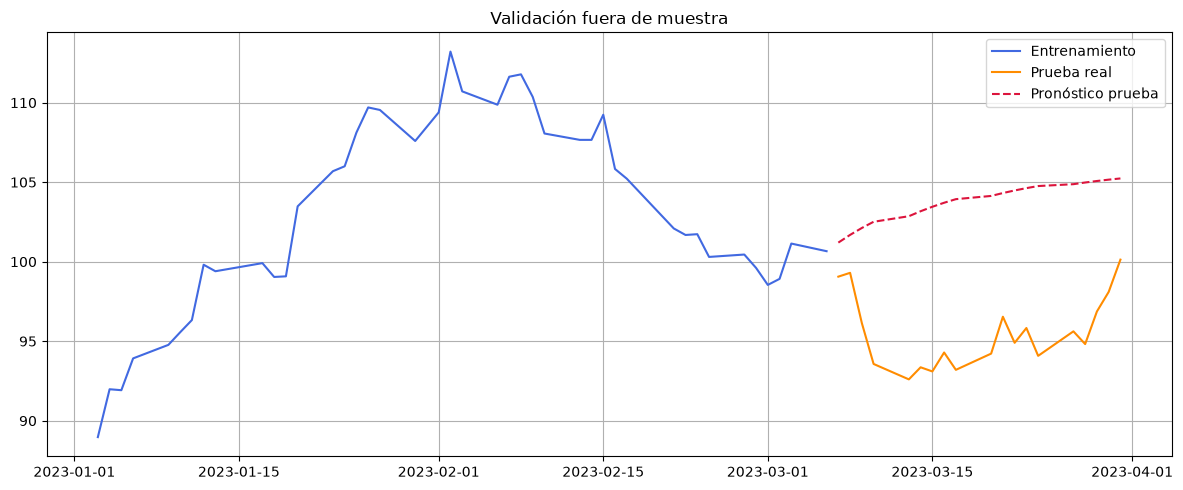

In [20]:
plt.plot(entrenamiento,color='royalblue',label='Entrenamiento');
plt.plot(prueba,color='darkorange',label='Prueba real');
plt.plot(pred_prueba,color='crimson',ls='--',label='Pronóstico prueba');
plt.title('Validación fuera de muestra');plt.legend();
guardar('09_validacion')

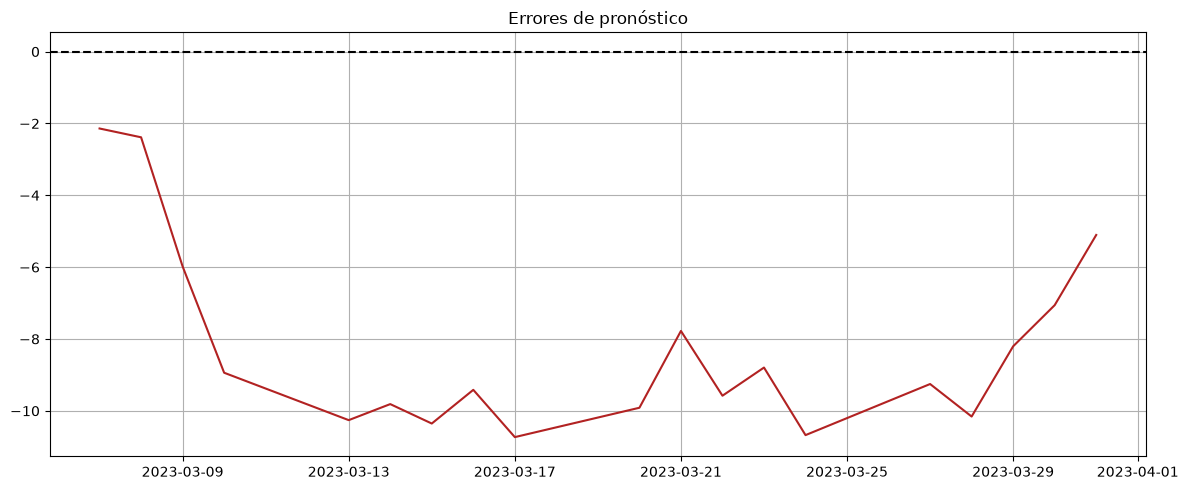

In [21]:
errores=prueba-pred_prueba;
plt.plot(errores.index,errores,color='firebrick');
plt.axhline(0,color='black',ls='--');
plt.title('Errores de pronóstico');
guardar('10_errores')

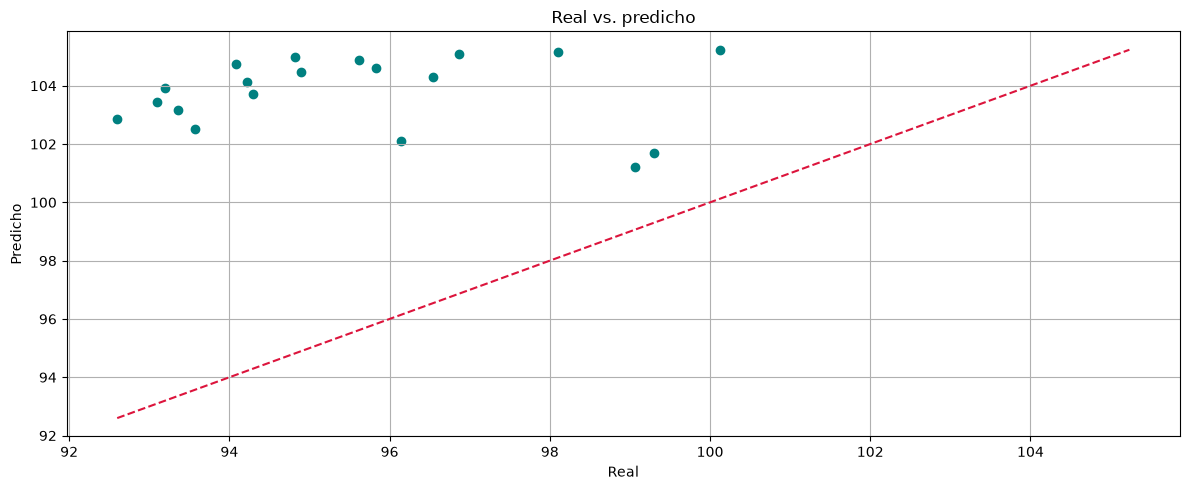

In [22]:
plt.scatter(prueba,pred_prueba,color='teal');
a=min(prueba.min(),pred_prueba.min());
b=max(prueba.max(),pred_prueba.max());
plt.plot([a,b],[a,b],color='crimson',ls='--');
plt.xlabel('Real');
plt.ylabel('Predicho');
plt.title('Real vs. predicho');
guardar('11_dispersion')

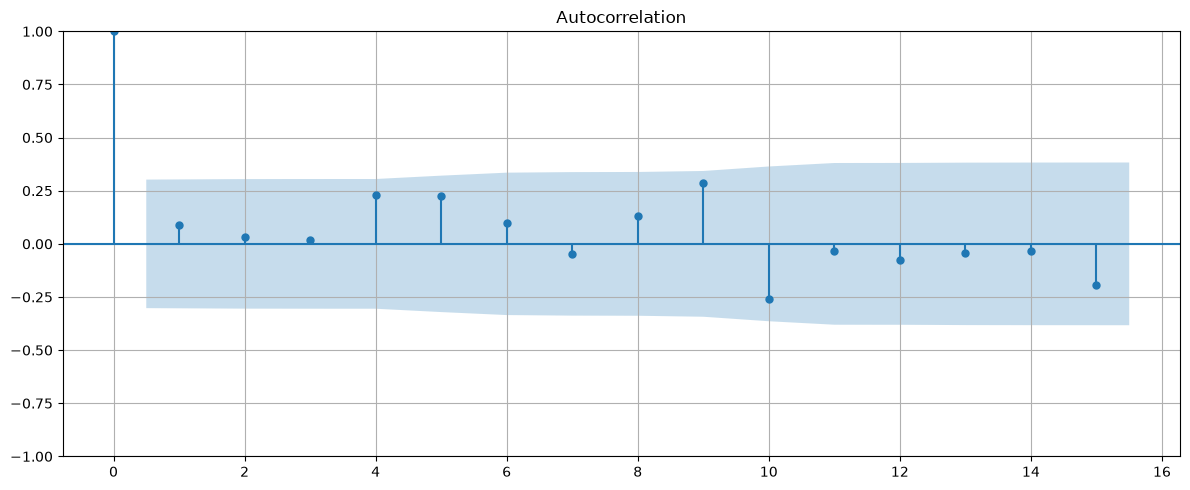

      lb_stat  lb_pvalue
10  15.548847   0.113296


In [23]:
residuos=pd.Series(modelo.resid).dropna();
fig,ax=plt.subplots();
plot_acf(residuos,lags=min(15,len(residuos)//2-1),ax=ax);
guardar('12_acf_residuos');
print(acorr_ljungbox(residuos,lags=[min(10,len(residuos)//4)],return_df=True))

##  Pronóstico de abril de 2023 e intervalos del 90%
Se reentrena con **todo enero-marzo**, una vez fijado p con entrenamiento. Se pronostican las sesiones bursátiles de abril. `get_prediction` genera intervalos de predicción del 90%, que reflejan incertidumbre de las observaciones futuras bajo los supuestos del AR. El calendario se obtiene de las fechas reales descargadas de abril; esas cotizaciones NO se utilizan para entrenar ni calcular los pronósticos.

In [24]:
modelo_final=AutoReg(train_period,lags=p_optimo,trend='c',old_names=False).fit()
if abril_real.empty: raise RuntimeError('No se pudieron determinar las sesiones de abril; descargue también abril 2023.')
h=len(abril_real)
pr=modelo_final.get_prediction(start=len(train_period),end=len(train_period)+h-1)
pron=np.asarray(pr.predicted_mean)
ci=np.asarray(pr.conf_int(alpha=0.10))
tabla_abril=pd.DataFrame({'Fecha':abril_real.index,'Pronostico_USD':pron,'Limite_inferior_90':ci[:,0],'Limite_superior_90':ci[:,1],'Real_USD':abril_real.to_numpy()})
tabla_abril['Error_USD']=tabla_abril.Real_USD-tabla_abril.Pronostico_USD
print(tabla_abril.round(3).to_string(index=False));tabla_abril.to_csv('DIS_pronosticos_abril_2023.csv',index=False)

     Fecha  Pronostico_USD  Limite_inferior_90  Limite_superior_90  Real_USD  Error_USD
2023-04-03         100.359              97.632             103.086     99.76     -0.599
2023-04-04         100.573              96.841             104.304     99.57     -1.003
2023-04-05         100.773              96.347             105.199     99.91     -0.863
2023-04-06         100.959              96.007             105.912     99.97     -0.989
2023-04-10         101.134              95.763             106.505    100.81     -0.324
2023-04-11         101.297              95.586             107.008    100.42     -0.877
2023-04-12         101.449              95.457             107.441     97.94     -3.509
2023-04-13         101.591              95.365             107.818    100.84     -0.751
2023-04-14         101.724              95.300             108.149     99.90     -1.824
2023-04-17         101.849              95.256             108.441    100.30     -1.549
2023-04-18         101.965      

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\deterministic.py:308: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a unit increment support extending. The index is set will contain the position relative to the data length.
  fcast_index = self._extend_index(index, steps, forecast_index)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be

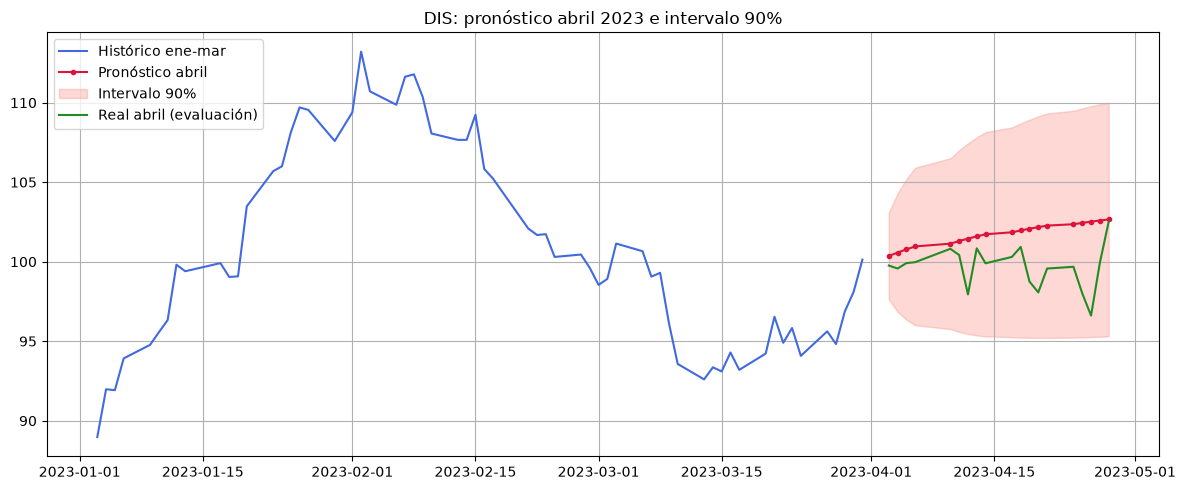

In [25]:
plt.plot(train_period.index,train_period,color='royalblue',label='Histórico ene-mar');
plt.plot(tabla_abril.Fecha,tabla_abril.Pronostico_USD,color='crimson',marker='o',ms=3,label='Pronóstico abril');
plt.fill_between(tabla_abril.Fecha,tabla_abril.Limite_inferior_90,tabla_abril.Limite_superior_90,color='salmon',alpha=.3,label='Intervalo 90%');
plt.plot(abril_real,color='forestgreen',label='Real abril (evaluación)');
plt.legend();
plt.title('DIS: pronóstico abril 2023 e intervalo 90%');
guardar('13_pronostico_abril')

In [26]:
print('Abril RMSE:',round(np.sqrt(mean_squared_error(abril_real,pron)),3),'MAE:',round(mean_absolute_error(abril_real,pron),3),'MAPE %:',round(np.mean(np.abs((abril_real.to_numpy()-pron)/abril_real.to_numpy()))*100,3));
print('Cobertura empírica del intervalo:',round(np.mean((abril_real.to_numpy()>=ci[:,0])&(abril_real.to_numpy()<=ci[:,1]))*100,2),'%')

Abril RMSE: 2.591 MAE: 2.067 MAPE %: 2.093
Cobertura empírica del intervalo: 100.0 %


##  Interpretación automática y conclusiones

In [27]:
print('Modelo seleccionado AR(%d); AIC: AR(%d); BIC: AR(%d)' % (p_optimo,p_aic,p_bic))
print('MAE=%.3f USD; RMSE=%.3f USD; MAPE=%.2f%%; R2=%.3f' % (mae,rmse,mape,r2))
print('RMSE de referencia ingenua: %.3f USD' % rmse_naive)
print('AR supera referencia ingenua' if rmse < rmse_naive else 'AR no supera referencia ingenua')
print('Posible raíz unitaria; considerar ARIMA' if adf[1]>=0.05 else 'ADF rechaza raíz unitaria')
print('Los intervalos al 90% dependen de los supuestos y la incertidumbre crece con el horizonte.')

Modelo seleccionado AR(1); AIC: AR(1); BIC: AR(1)
MAE=8.239 USD; RMSE=8.622 USD; MAPE=8.68%; R2=-14.282
RMSE de referencia ingenua: 5.552 USD
AR no supera referencia ingenua
ADF rechaza raíz unitaria
Los intervalos al 90% dependen de los supuestos y la incertidumbre crece con el horizonte.
